# Sentiment Analysis Using Machine Learning

## Objective
Build a machine learning model that classifies text reviews
as Positive or Negative.

## Introduction
Sentiment Analysis is a Natural Language Processing (NLP)
technique used to identify emotions or opinions in text data.

## Dataset
A sample dataset containing text reviews and their sentiment labels.

## Machine Learning Model
Logistic Regression

## Techniques Used
1. Text Cleaning
2. Lowercasing
3. Tokenization
4. TF-IDF Vectorization
5. Model Training
6. Model Evaluation

## Evaluation Metrics
1. Accuracy
2. Precision
3. Recall
4. F1 Score
5. Confusion Matrix

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pickle

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = {
    "text": [
        "I love this product",
        "This product is amazing",
        "The service was excellent",
        "I am very happy with this purchase",
        "The quality is fantastic",
        "I really enjoyed this experience",
        "This is a wonderful product",
        "The delivery was very fast",
        "I am satisfied with the service",
        "The movie was absolutely great",
        "I hate this product",
        "This product is terrible",
        "The service was very poor",
        "I am disappointed with this purchase",
        "The quality is very bad",
        "I did not enjoy this experience",
        "This is a horrible product",
        "The delivery was very slow",
        "I am unhappy with the service",
        "The movie was absolutely boring"
    ],

    "sentiment": [
        "Positive", "Positive", "Positive", "Positive", "Positive",
        "Positive", "Positive", "Positive", "Positive", "Positive",
        "Negative", "Negative", "Negative", "Negative", "Negative",
        "Negative", "Negative", "Negative", "Negative", "Negative"
    ]
}

df = pd.DataFrame(data)

display(df)

,text,sentiment
0,I love this product,Positive
1,This product is amazing,Positive
2,The service was excellent,Positive
3,I am very happy with this purchase,Positive
4,The quality is fantastic,Positive
5,I really enjoyed this experience,Positive
6,This is a wonderful product,Positive
7,The delivery was very fast,Positive
8,I am satisfied with the service,Positive
9,The movie was absolutely great,Positive


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Reviews:")
display(df.head())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Dataset Shape: (20, 2)

First 5 Reviews:


,text,sentiment
0,I love this product,Positive
1,This product is amazing,Positive
2,The service was excellent,Positive
3,I am very happy with this purchase,Positive
4,The quality is fantastic,Positive



Sentiment Distribution:
sentiment
Positive    10
Negative    10
Name: count, dtype: int64


In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["cleaned_text"] = df["text"].apply(clean_text)

display(df)

,text,sentiment,cleaned_text
0,I love this product,Positive,i love this product
1,This product is amazing,Positive,this product is amazing
2,The service was excellent,Positive,the service was excellent
3,I am very happy with this purchase,Positive,i am very happy with this purchase
4,The quality is fantastic,Positive,the quality is fantastic
5,I really enjoyed this experience,Positive,i really enjoyed this experience
6,This is a wonderful product,Positive,this is a wonderful product
7,The delivery was very fast,Positive,the delivery was very fast
8,I am satisfied with the service,Positive,i am satisfied with the service
9,The movie was absolutely great,Positive,the movie was absolutely great


In [5]:
X = df["cleaned_text"]
y = df["sentiment"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


0                   i love this product
1               this product is amazing
2             the service was excellent
3    i am very happy with this purchase
4              the quality is fantastic
Name: cleaned_text, dtype: str

Target:


0    Positive
1    Positive
2    Positive
3    Positive
4    Positive
Name: sentiment, dtype: str

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


In [7]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (16, 34)
Testing data shape: (4, 34)


In [8]:
model = LogisticRegression(random_state=42)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
y_pred = model.predict(X_test_tfidf)

print("Actual Sentiments:")
print(y_test.values)

print("\nPredicted Sentiments:")
print(y_pred)

Actual Sentiments:
<StringArray>
['Negative', 'Negative', 'Positive', 'Positive']
Length: 4, dtype: str

Predicted Sentiments:
['Positive' 'Positive' 'Negative' 'Positive']


In [10]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Positive")
recall = recall_score(y_test, y_pred, pos_label="Positive")
f1 = f1_score(y_test, y_pred, pos_label="Positive")

print("Accuracy:", round(accuracy, 2))
print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))
print("F1 Score:", round(f1, 2))

Accuracy: 0.25
Precision: 0.33
Recall: 0.5
F1 Score: 0.4


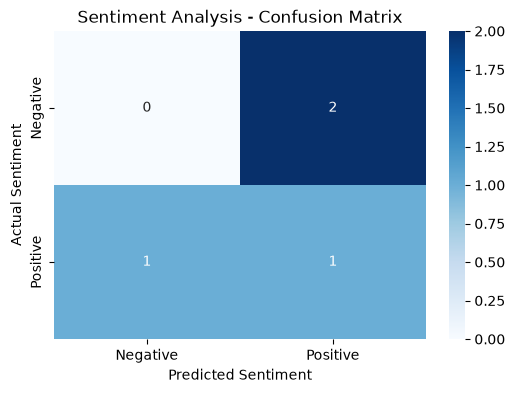

In [11]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Positive"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()

In [12]:
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         2
    Positive       0.33      0.50      0.40         2

    accuracy                           0.25         4
   macro avg       0.17      0.25      0.20         4
weighted avg       0.17      0.25      0.20         4



In [13]:
user_review = "This product is really amazing"

cleaned_review = clean_text(user_review)

review_tfidf = tfidf.transform([cleaned_review])

prediction = model.predict(review_tfidf)

print("Review:", user_review)
print("Predicted Sentiment:", prediction[0])

Review: This product is really amazing
Predicted Sentiment: Positive


In [14]:
# Save the trained model
with open("sentiment_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save the TF-IDF vectorizer
with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

# Save the dataset
df.to_csv("sentiment_dataset.csv", index=False)

print("Model saved successfully!")
print("TF-IDF Vectorizer saved successfully!")
print("Dataset saved successfully!")

Model saved successfully!
TF-IDF Vectorizer saved successfully!
Dataset saved successfully!


In [15]:
from pathlib import Path

files = [
    "sentiment_model.pkl",
    "tfidf_vectorizer.pkl",
    "sentiment_dataset.csv"
]

for filename in files:
    if Path(filename).exists():
        print(filename, "- Saved successfully!")
    else:
        print(filename, "- File not found!")

sentiment_model.pkl - Saved successfully!
tfidf_vectorizer.pkl - Saved successfully!
sentiment_dataset.csv - Saved successfully!


## Conclusion

In this project, we successfully developed a Sentiment Analysis
model using Natural Language Processing and Machine Learning.

We performed:
1. Text Cleaning
2. Lowercasing
3. TF-IDF Vectorization
4. Train-Test Splitting
5. Logistic Regression Model Training
6. Model Evaluation
7. Sentiment Prediction
8. Model Saving

The model predicts whether a text review is Positive or Negative.

This project helped us understand how NLP and Machine Learning
can be used to classify text data.

Note: The dataset contains only 20 sample reviews.
More real-world data is required to build a reliable model.